In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
df = pd.read_csv("../data/arxiv_papers_preprocessed_v2.csv")

In [3]:
df.head()

,request_id,retrieved_at,domain,arxiv_id,title,summary,authors,primary_category,categories,published,updated,abs_url,pdf_url,text,text_clean,text_clean_embeddings
0,https://arxiv.org/api/Nn9ZAl7r/hPtw2SqI662/Ri9DWc,2026-10-30T05:02:17+00:00,cs,2610.40655v1,Elucidating the Design Space of LM Data Attrib...,Data attribution methods for Language Models (...,Steven Yu; Sheng-Yu Wang; Kimia Hamidieh; Anto...,cs.CL,cs.CL,2026-10-29T17:59:53Z,2026-10-29T17:59:53Z,http://arxiv.org/abs/2610.40655v1,https://arxiv.org/pdf/2610.40655v1,Elucidating the Design Space of LM Data Attrib...,elucidating design space lm data attribution d...,[ 2.36154534e-02 1.35993650e-02 -2.78382376e-...
1,https://arxiv.org/api/Nn9ZAl7r/hPtw2SqI662/Ri9DWc,2026-10-30T05:02:17+00:00,cs,2610.40654v1,Propose-Filter-Release: Scaling Noise to Typic...,An estimator can be accurate and stable on typ...,Moshe Shenfeld; Eliad Tsfadia; Katrina Ligett,cs.LG,cs.LG,2026-10-29T17:59:49Z,2026-10-29T17:59:49Z,http://arxiv.org/abs/2610.40654v1,https://arxiv.org/pdf/2610.40654v1,Propose-Filter-Release: Scaling Noise to Typic...,propose filter release scaling noise typical s...,[-8.77295714e-03 1.24642206e-02 2.35526934e-...
2,https://arxiv.org/api/Nn9ZAl7r/hPtw2SqI662/Ri9DWc,2026-10-30T05:02:17+00:00,cs,2610.40653v1,Micro-Edits: Computational Support for Fine-Sc...,"In film editing, every frame matters. While ma...",Nhan Tran; Hijung Valentina Shin; Abe Davis; M...,cs.HC,cs.HC; cs.CV,2026-10-29T17:59:49Z,2026-10-29T17:59:49Z,http://arxiv.org/abs/2610.40653v1,https://arxiv.org/pdf/2610.40653v1,Micro-Edits: Computational Support for Fine-Sc...,micro edits computational support fine scale e...,[ 1.30903404e-02 3.87951992e-02 -1.13366137e-...
3,https://arxiv.org/api/Nn9ZAl7r/hPtw2SqI662/Ri9DWc,2026-10-30T05:02:17+00:00,cs,2610.40649v1,Rethinking Neural Thickets Without Weight Pert...,The Neural Thickets hypothesis posits that pre...,Nicolas Dufour; Elouan Gardès; Amil Dravid; Pa...,cs.LG,cs.LG; cs.AI; cs.CV,2026-10-29T17:59:29Z,2026-10-29T17:59:29Z,http://arxiv.org/abs/2610.40649v1,https://arxiv.org/pdf/2610.40649v1,Rethinking Neural Thickets Without Weight Pert...,rethinking neural thicket without weight pertu...,[ 7.17344554e-03 -7.23641366e-02 -1.14649329e-...
4,https://arxiv.org/api/Nn9ZAl7r/hPtw2SqI662/Ri9DWc,2026-10-30T05:02:17+00:00,cs,2610.40647v1,"Read, Allocate, Route: Role-Coupled Tokenizati...",Pixel-space generative Transformers typically ...,Jiongfan Yang; Weichen Fan; Haiwen Diao; Zhong...,cs.CV,cs.CV; cs.AI; cs.LG; cs.NE,2026-10-29T17:59:21Z,2026-10-29T17:59:21Z,http://arxiv.org/abs/2610.40647v1,https://arxiv.org/pdf/2610.40647v1,"Read, Allocate, Route: Role-Coupled Tokenizati...",read allocate route role coupled tokenization ...,[-1.93801709e-02 -3.73318233e-02 -8.91015865e-...


In [4]:
df["domain"].value_counts(normalize=True).mul(100).round(2)

domain
cs         25.0
q-bio      25.0
physics    25.0
eess       25.0
Name: proportion, dtype: float64

In [5]:
df["primary_category"].value_counts(normalize=True).mul(100).round(2)

primary_category
eess.SY             9.90
eess.SP             8.80
q-bio.NC            7.45
q-bio.QM            5.70
physics.optics      5.35
                    ... 
cs.SC               0.05
cs.ET               0.05
cs.SI               0.05
physics.atm-clus    0.05
physics.pop-ph      0.05
Name: proportion, Length: 68, dtype: float64

In [6]:
import numpy as np

def clean_spaces_embedding(text_string):
    cleaned = text_string.strip("[]")
    return np.fromstring(cleaned, sep=' ')


df['text_clean_embeddings'] = df['text_clean_embeddings'].apply(clean_spaces_embedding)

X = np.vstack(df['text_clean_embeddings'].values).astype('float32')

print("Forme finale de la matrice :", X.shape)


Forme finale de la matrice : (2000, 768)


In [7]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(X_scaled[:2])

[[ 1.6021042   0.69093734 -1.1385304  ... -0.7987721  -0.16493836
  -0.79606473]
 [ 0.20039421  0.64546365  0.9301421  ...  0.2768133  -2.3077185
  -0.54432124]]


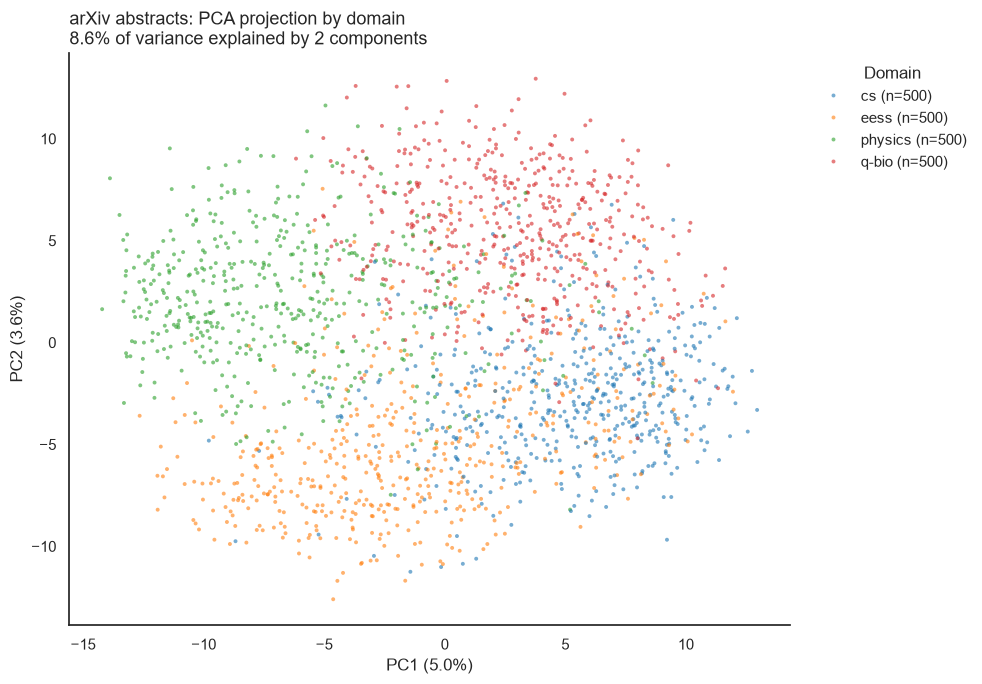

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

sns.set_theme(style="white", context="notebook")

plot_df = (
    df.assign(pc1=X_pca[:, 0], pc2=X_pca[:, 1])
    .sample(frac=1, random_state=42)
)

counts = plot_df["domain"].value_counts()
plot_df["domain_n"] = plot_df["domain"].map(lambda d: f"{d} (n={counts[d]})")

var = pca.explained_variance_ratio_ * 100

fig, ax = plt.subplots(figsize=(10, 7))
sns.scatterplot(
    data=plot_df,
    x="pc1", y="pc2",
    hue="domain_n",
    hue_order=sorted(plot_df["domain_n"].unique()),
    palette="tab10",
    s=8, alpha=0.6, linewidth=0, rasterized=True,
    ax=ax,
)

ax.set_title(
    "arXiv abstracts: PCA projection by domain\n"
    f"{var.sum():.1f}% of variance explained by 2 components",
    loc="left", fontsize=13,
)
ax.set(xlabel=f"PC1 ({var[0]:.1f}%)", ylabel=f"PC2 ({var[1]:.1f}%)")

sns.move_legend(ax, "upper left", bbox_to_anchor=(1.02, 1), title="Domain", frameon=False)
sns.despine()
plt.tight_layout()
plt.show()

In [9]:
print("Explained variance:", pca.explained_variance_ratio_)
print("Cumulative:", np.cumsum(pca.explained_variance_ratio_))

Explained variance: [0.04999137 0.03563746]
Cumulative: [0.04999137 0.08562884]


c:\Users\T14s\Arix-Research-Paper-Recommendation-System\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


(2000, 2)


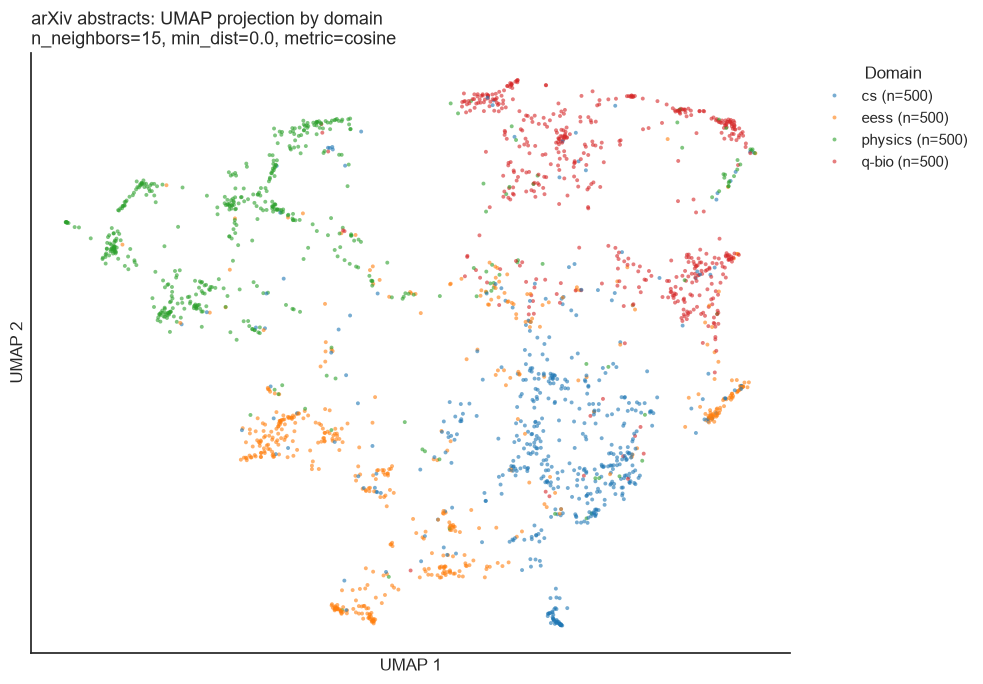

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

import umap

reducer = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.0,
    metric="cosine",
    random_state=42, 
)
X_umap = reducer.fit_transform(X)
print(X_umap.shape)

sns.set_theme(style="white", context="notebook")

plot_df = (
    df.assign(umap_1=X_umap[:, 0], umap_2=X_umap[:, 1])
    .sample(frac=1, random_state=42)
)

counts = plot_df["domain"].value_counts()
plot_df["domain_n"] = plot_df["domain"].map(lambda d: f"{d} (n={counts[d]})")

fig, ax = plt.subplots(figsize=(10, 7))
sns.scatterplot(
    data=plot_df,
    x="umap_1", y="umap_2",
    hue="domain_n",
    hue_order=sorted(plot_df["domain_n"].unique()),
    palette="tab10",
    s=8, alpha=0.6, linewidth=0, rasterized=True,
    ax=ax,
)

ax.set_title(
    "arXiv abstracts: UMAP projection by domain\n"
    "n_neighbors=15, min_dist=0.0, metric=cosine",
    loc="left", fontsize=13,
)
ax.set(xlabel="UMAP 1", ylabel="UMAP 2", xticks=[], yticks=[])

sns.move_legend(ax, "upper left", bbox_to_anchor=(1.02, 1), title="Domain", frameon=False)
sns.despine()
plt.tight_layout()
plt.show()

In [12]:
import umap
import plotly.express as px

reducer_3d = umap.UMAP(
    n_components=3,
    n_neighbors=15,
    min_dist=0.0,
    metric="cosine",
    random_state=42,
)
X_umap_3d = reducer_3d.fit_transform(X)

plot_df = (
    df.assign(umap_1=X_umap_3d[:, 0], umap_2=X_umap_3d[:, 1], umap_3=X_umap_3d[:, 2])
    .sample(frac=1, random_state=42)
)

counts = plot_df["domain"].value_counts()
plot_df["domain_n"] = plot_df["domain"].map(lambda d: f"{d} (n={counts[d]})")

fig = px.scatter_3d(
    plot_df,
    x="umap_1", y="umap_2", z="umap_3",
    color="domain_n",
    category_orders={"domain_n": sorted(plot_df["domain_n"].unique())},
    hover_name="title",
    hover_data={"primary_category": True, "umap_1": False, "umap_2": False, "umap_3": False},
    opacity=0.7,
    title="arXiv abstracts: 3D UMAP projection by domain<br>"
          "<sup>n_neighbors=15, min_dist=0.0, metric=cosine</sup>",
    width=950, height=750,
)
fig.update_traces(marker=dict(size=2.5))
fig.update_layout(
    legend_title_text="Domain",
    scene=dict(xaxis_title="UMAP 1", yaxis_title="UMAP 2", zaxis_title="UMAP 3"),
)
fig.show()

c:\Users\T14s\Arix-Research-Paper-Recommendation-System\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
